<a href="https://colab.research.google.com/github/Tan1725/CreditPulse-AI/blob/main/Credit_Card_Fraud_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#TI Data pre-processing

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler

df = pd.read_csv("credit_card_fraud_dataset.csv")

print("First 5 Rows")
print(df.head())

print("\nDataset Information")
print(df.info())

print("\nDataset Shape")
print(df.shape)

print("\nColumn Names")
print(df.columns)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("\nStatistical Summary")
print(df.describe())

df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])

df["Year"] = df["TransactionDate"].dt.year
df["Month"] = df["TransactionDate"].dt.month
df["Day"] = df["TransactionDate"].dt.day
df["Hour"] = df["TransactionDate"].dt.hour

encoder = LabelEncoder()

df["TransactionType"] = encoder.fit_transform(df["TransactionType"])
df["Location"] = encoder.fit_transform(df["Location"])

scaler = StandardScaler()
df["Amount"] = scaler.fit_transform(df[["Amount"]])

df.drop(["TransactionID", "TransactionDate"], axis=1, inplace=True)

print("\nProcessed Dataset")
print(df.head())

df.to_csv("processed_credit_card_fraud.csv", index=False)

print("\nPreprocessing Completed Successfully!")

First 5 Rows
   TransactionID             TransactionDate   Amount  MerchantID  \
0              1  2024-04-03 14:15:35.462794  4189.27         688   
1              2  2024-03-19 13:20:35.462824  2659.71         109   
2              3  2024-01-08 10:08:35.462834   784.00         394   
3              4  2024-04-13 23:50:35.462850  3514.40         944   
4              5  2024-07-12 18:51:35.462858   369.07         475   

  TransactionType      Location  IsFraud  
0          refund   San Antonio        0  
1          refund        Dallas        0  
2        purchase      New York        0  
3        purchase  Philadelphia        0  
4        purchase       Phoenix        0  

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   TransactionID    100000 non-null  int64  
 1   TransactionDate  100000 non-null  obje

#T2 Linear Regression

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

df = pd.read_csv("processed_credit_card_fraud.csv")

X = df.drop("Amount", axis=1)
y = df["Amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Absolute Error :", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error  :", mean_squared_error(y_test, y_pred))
print("R2 Score            :", r2_score(y_test, y_pred))

comparison = pd.DataFrame({
    "Actual Amount": y_test.values,
    "Predicted Amount": y_pred
})

print("\nActual vs Predicted")
print(comparison.head())

sample = X.iloc[[0]]
prediction = model.predict(sample)

print("\nPrediction for First Transaction")
print(prediction)

Mean Absolute Error : 0.8649950191990483
Mean Squared Error  : 0.9984337428804587
R2 Score            : -9.315974254486825e-05

Actual vs Predicted
   Actual Amount  Predicted Amount
0       1.063587          0.023986
1       0.361699          0.003795
2      -1.617622          0.000587
3       0.035591         -0.012004
4       0.551125          0.002910

Prediction for First Transaction
[-0.00113125]


#T3 Cross Validation


In [ ]:
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
df = pd.read_csv("processed_credit_card_fraud.csv")
X = df.drop(["Amount", "MerchantID"], axis=1)
y = df["Amount"]
model = LinearRegression()
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scores = cross_val_score(
    model,
    X,
    y,
    cv=kfold,
    scoring="r2"
)
print("R² Scores for each fold:")
print(scores)
print("\nAverage R² Score:")
print(scores.mean())
print("\nStandard Deviation:")
print(scores.std())

R² Scores for each fold:
[-9.24463486e-05  3.37961579e-05 -1.85068160e-04 -3.27520059e-04
 -4.63077705e-04]

Average R² Score:
-0.00020686322290592863

Standard Deviation:
0.0001741764142202604


#T4 Performance metrics


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

Performance Metrics
-------------------
Accuracy: 0.99
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Confusion Matrix
----------------
[[19800     0]
 [  200     0]]

Classification Report
---------------------
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     19800
           1       0.00      0.00      0.00       200

    accuracy                           0.99     20000
   macro avg       0.49      0.50      0.50     20000
weighted avg       0.98      0.99      0.99     20000



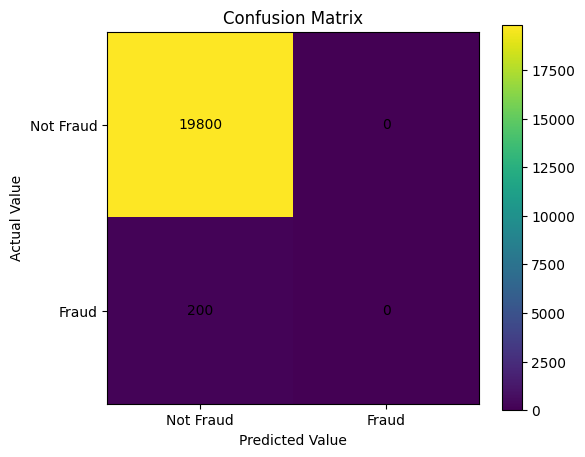

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

import matplotlib.pyplot as plt

df = pd.read_csv("processed_credit_card_fraud.csv")

X = df.drop("IsFraud", axis=1)
y = df["IsFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Performance Metrics")
print("-------------------")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nConfusion Matrix")
print("----------------")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nClassification Report")
print("---------------------")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")

plt.xticks([0, 1], ["Not Fraud", "Fraud"])
plt.yticks([0, 1], ["Not Fraud", "Fraud"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()

plt.show()


#T5 Linear Regression with Multiple Variables


Multiple Linear Regression
--------------------------
Intercept: -51.97097366956055

Coefficients:
TransactionType : -0.003417082061934126
Location : -0.0003879737185472615
IsFraud : 0.02048897365688706
Year : 0.02567547194905198
Month : 0.0015595797067762915
Day : 2.266623836533958e-05
Hour : 0.0001734296581701133

Performance Metrics
-------------------
MAE: 0.8649949489331097
MSE: 0.9984330306702286
R² Score: -9.244634860716694e-05


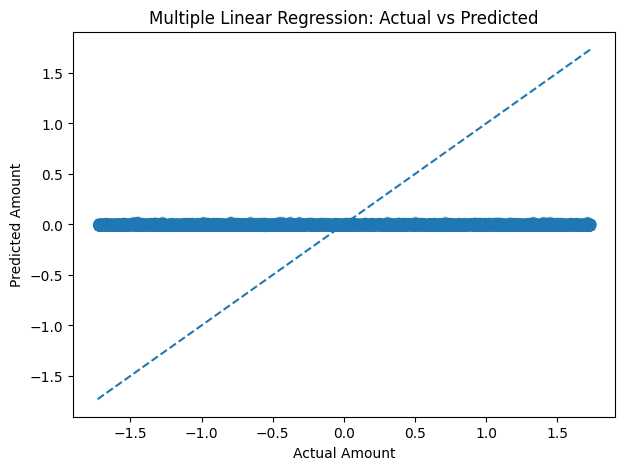

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt

df = pd.read_csv("processed_credit_card_fraud.csv")

X = df.drop(["Amount", "MerchantID"], axis=1)

y = df["Amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Multiple Linear Regression")
print("--------------------------")

print("Intercept:", model.intercept_)

print("\nCoefficients:")
for column, coefficient in zip(X.columns, model.coef_):
    print(column, ":", coefficient)

print("\nPerformance Metrics")
print("-------------------")

print("MAE:", mean_absolute_error(y_test, y_pred))

print("MSE:", mean_squared_error(y_test, y_pred))

print("R² Score:", r2_score(y_test, y_pred))

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Amount")
plt.ylabel("Predicted Amount")
plt.title("Multiple Linear Regression: Actual vs Predicted")

plt.show()

#T6 Logistic Regression


Logistic Regression
-------------------

Actual values:
[0 0 0 0 0 0 0 0 0 0]

Predicted values:
[0 0 0 0 0 0 0 0 0 0]

Fraud Probabilities:
[0.01091289 0.00969582 0.00926398 0.0102626  0.00903468 0.01019699
 0.00974227 0.00887087 0.01066989 0.01004048]

Performance Metrics
-------------------
Accuracy: 0.99
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Confusion Matrix
----------------
[[19800     0]
 [  200     0]]


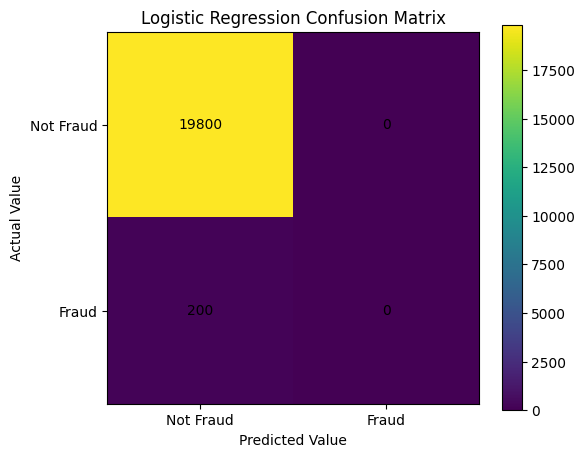

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt

df = pd.read_csv("processed_credit_card_fraud.csv")

X = df.drop("IsFraud", axis=1)

y = df["IsFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Logistic Regression")
print("-------------------")

print("\nActual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(y_pred[:10])

print("\nFraud Probabilities:")
print(y_probability[:10])

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nPerformance Metrics")
print("-------------------")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix")
print("----------------")
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")

plt.xticks([0, 1], ["Not Fraud", "Fraud"])
plt.yticks([0, 1], ["Not Fraud", "Fraud"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()

plt.show()

# T7 PCA

Original Dataset Shape: (150, 4)
Reduced Dataset Shape: (150, 2)

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Variance Retained:
0.9581320720000166


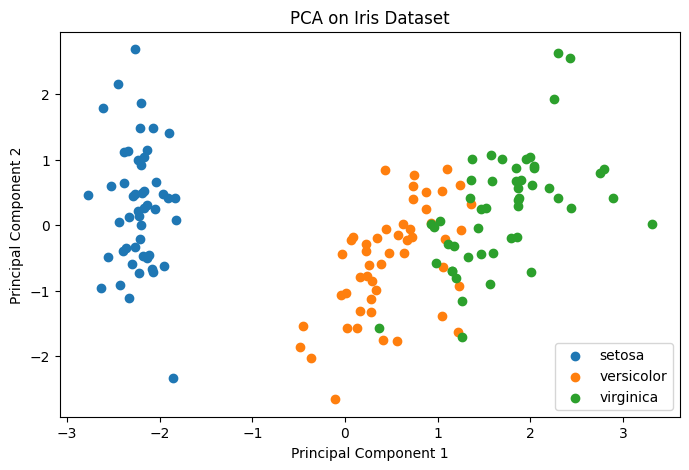

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()

X = iris.data
y = iris.target

print("Original Dataset Shape:", X.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Reduced Dataset Shape:", X_pca.shape)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 5))

for i, name in enumerate(iris.target_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=name
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Iris Dataset")
plt.legend()
plt.show()

# T8 Naive bayes


Naive Bayes Classification
--------------------------

Actual Values:
[0 2 1 1 0 1 0 0 2 1]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1]

Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


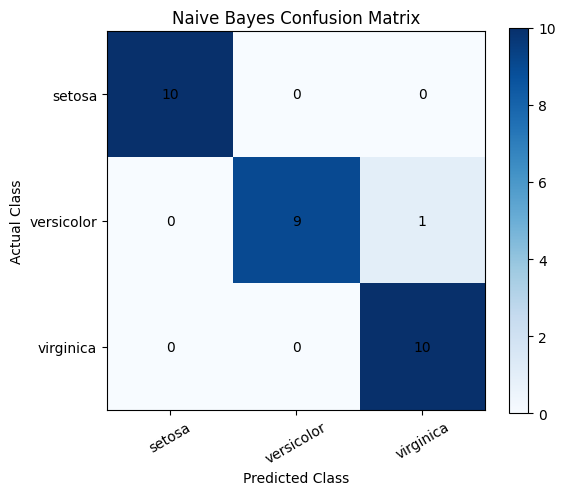


New Flower Prediction:
setosa


In [ ]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = GaussianNB()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Naive Bayes Classification")
print("--------------------------")

print("\nActual Values:")
print(y_test[:10])

print("\nPredicted Values:")
print(y_pred[:10])

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(3), iris.target_names, rotation=30)
plt.yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

sample = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(sample)

print("\nNew Flower Prediction:")
print(iris.target_names[prediction[0]])

# T9 SVM

Support Vector Machine Classification
-------------------------------------

Actual Values:
[0 2 1 1 0 1 0 0 2 1]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1]

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


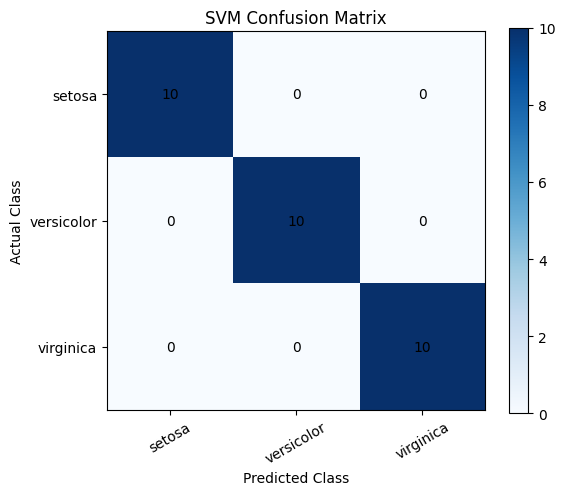


New Flower Prediction:
setosa


In [ ]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Support Vector Machine Classification")
print("-------------------------------------")

print("\nActual Values:")
print(y_test[:10])

print("\nPredicted Values:")
print(y_pred[:10])

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(3), iris.target_names, rotation=30)
plt.yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

sample = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(sample)

print("\nNew Flower Prediction:")
print(iris.target_names[prediction[0]])